Neural Computation (Dubai) – Continuous Assessment, Fall 2026
Group: **PG10 **(g = 10)

Group Name: **Neuronauts**

Programme: MSc

Group Members and Contributions:

1. **Syed Abdul Haadi**:
Student ID: 3180291
Main Contribution: Section 1 – Data Pipeline and Reproducibility

2. **Haroon Mohammed**
Student ID: [ID]
Main Contribution: Section 2 – Baselines and Parameter Counts

3. **Waleed Abdullah**
Student ID: [ID]
Main Contribution: Section 3 – Batch Size and Learning Rate Study

4. **Ved Visal**
Student ID: [ID]
Main Contribution: Section 4 – Own Model and Test Evaluation

In [ ]:
!pip install -q datasets nltk

In [ ]:
import random, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import datasets as hf_datasets
from datasets import load_dataset
import sklearn
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import wordnet as wn

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Python  :", platform.python_version())
print("PyTorch :", torch.__version__)
print("datasets:", hf_datasets.__version__)
print("sklearn :", sklearn.__version__)
print("NumPy   :", np.__version__)
print("Device  :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else device.type.upper())

Python  : 3.13.16
PyTorch : 2.14.1+cu130
datasets: 4.8.5
sklearn : 1.6.1
NumPy   : 2.4.6
Device  : cuda - Tesla T4


In [ ]:
g = 10            # group PG10
SEED = g

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

1. Data preparation



In [ ]:
classes = [(3 * g + 17 * k) % 200 for k in range(10)]
relabel = {c: i for i, c in enumerate(classes)}      # original label -> 0..9
print("Original labels:", classes)
print("Relabel map    :", relabel)

ds = load_dataset("zh-plus/tiny-imagenet")           # splits: 'train' and 'valid'
wnids = ds["train"].features["label"].names           # WordNet IDs

train_full = ds["train"].filter(lambda y: y in relabel, input_columns="label")
train_full = train_full.map(lambda y: {"label": relabel[y]}, input_columns="label")
print(len(train_full), "training images")            # expect 5000
assert len(train_full) == 5000

# NOTE: ds["valid"] is our TEST set. It is not touched until Section 4.

try:
    nltk.download("wordnet", quiet=True)
    syn = lambda w: wn.synset_from_pos_and_offset("n", int(w[1:]))
    class_names = [syn(wnids[c]).lemma_names()[0] for c in classes]
except LookupError:
    class_names = [wnids[c] for c in classes]

for i, c in enumerate(classes):
    print(f"{i}: original label {c:3d} ({wnids[c]}) - {class_names[i]}")

Original labels: [30, 47, 64, 81, 98, 115, 132, 149, 166, 183]
Relabel map    : {30: 0, 47: 1, 64: 2, 81: 3, 98: 4, 115: 5, 132: 6, 149: 7, 166: 8, 183: 9}


README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-1359597a978bc4(…): reconstructing file:   0%|          |  0.00B /  146MB            

data/train-00000-of-00001-1359597a978bc4(…): downloading bytes:           |  0.00B            

data/valid-00000-of-00001-70d52db3c749a9(…): reconstructing file:   0%|          |  0.00B / 14.6MB            

... (2 outputs left out)

Generating valid split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

5000 training images
0: original label  30 (n02125311) - cougar
1: original label  47 (n02423022) - gazelle
2: original label  64 (n02814533) - beach_wagon
3: original label  81 (n03014705) - chest
4: original label  98 (n03424325) - gasmask
5: original label 115 (n03837869) - obelisk
6: original label 132 (n04118538) - rugby_ball
7: original label 149 (n04398044) - teapot
8: original label 166 (n07056680) - reel
9: original label 183 (n07920052) - espresso


In [ ]:
!pip install -q datasets nltk

In [ ]:
import random, platform
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import datasets as hf_datasets
from datasets import load_dataset
import sklearn
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import wordnet as wn

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Python  :", platform.python_version())
print("PyTorch :", torch.__version__)
print("datasets:", hf_datasets.__version__)
print("sklearn :", sklearn.__version__)
print("NumPy   :", np.__version__)
print("Device  :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else device.type.upper())

Python  : 3.13.16
PyTorch : 2.14.1+cu130
datasets: 4.8.5
sklearn : 1.6.1
NumPy   : 2.4.6
Device  : cuda - Tesla T4


In [ ]:
g = 10            # group PG10
SEED = g

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

1. Data preparation



In [ ]:
classes = [(3 * g + 17 * k) % 200 for k in range(10)]
relabel = {c: i for i, c in enumerate(classes)}      # original label -> 0..9
print("Original labels:", classes)
print("Relabel map    :", relabel)

ds = load_dataset("zh-plus/tiny-imagenet")           # splits: 'train' and 'valid'
wnids = ds["train"].features["label"].names           # WordNet IDs

train_full = ds["train"].filter(lambda y: y in relabel, input_columns="label")
train_full = train_full.map(lambda y: {"label": relabel[y]}, input_columns="label")
print(len(train_full), "training images")            # expect 5000
assert len(train_full) == 5000

# NOTE: ds["valid"] is our TEST set. It is not touched until Section 4.

try:
    nltk.download("wordnet", quiet=True)
    syn = lambda w: wn.synset_from_pos_and_offset("n", int(w[1:]))
    class_names = [syn(wnids[c]).lemma_names()[0] for c in classes]
except LookupError:
    class_names = [wnids[c] for c in classes]

for i, c in enumerate(classes):
    print(f"{i}: original label {c:3d} ({wnids[c]}) - {class_names[i]}")

Original labels: [30, 47, 64, 81, 98, 115, 132, 149, 166, 183]
Relabel map    : {30: 0, 47: 1, 64: 2, 81: 3, 98: 4, 115: 5, 132: 6, 149: 7, 166: 8, 183: 9}


README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-1359597a978bc4(…): reconstructing file:   0%|          |  0.00B /  146MB            

data/train-00000-of-00001-1359597a978bc4(…): downloading bytes:           |  0.00B            

data/valid-00000-of-00001-70d52db3c749a9(…): reconstructing file:   0%|          |  0.00B / 14.6MB            

... (2 outputs left out)

Generating valid split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

5000 training images
0: original label  30 (n02125311) - cougar
1: original label  47 (n02423022) - gazelle
2: original label  64 (n02814533) - beach_wagon
3: original label  81 (n03014705) - chest
4: original label  98 (n03424325) - gasmask
5: original label 115 (n03837869) - obelisk
6: original label 132 (n04118538) - rugby_ball
7: original label 149 (n04398044) - teapot
8: original label 166 (n07056680) - reel
9: original label 183 (n07920052) - espresso


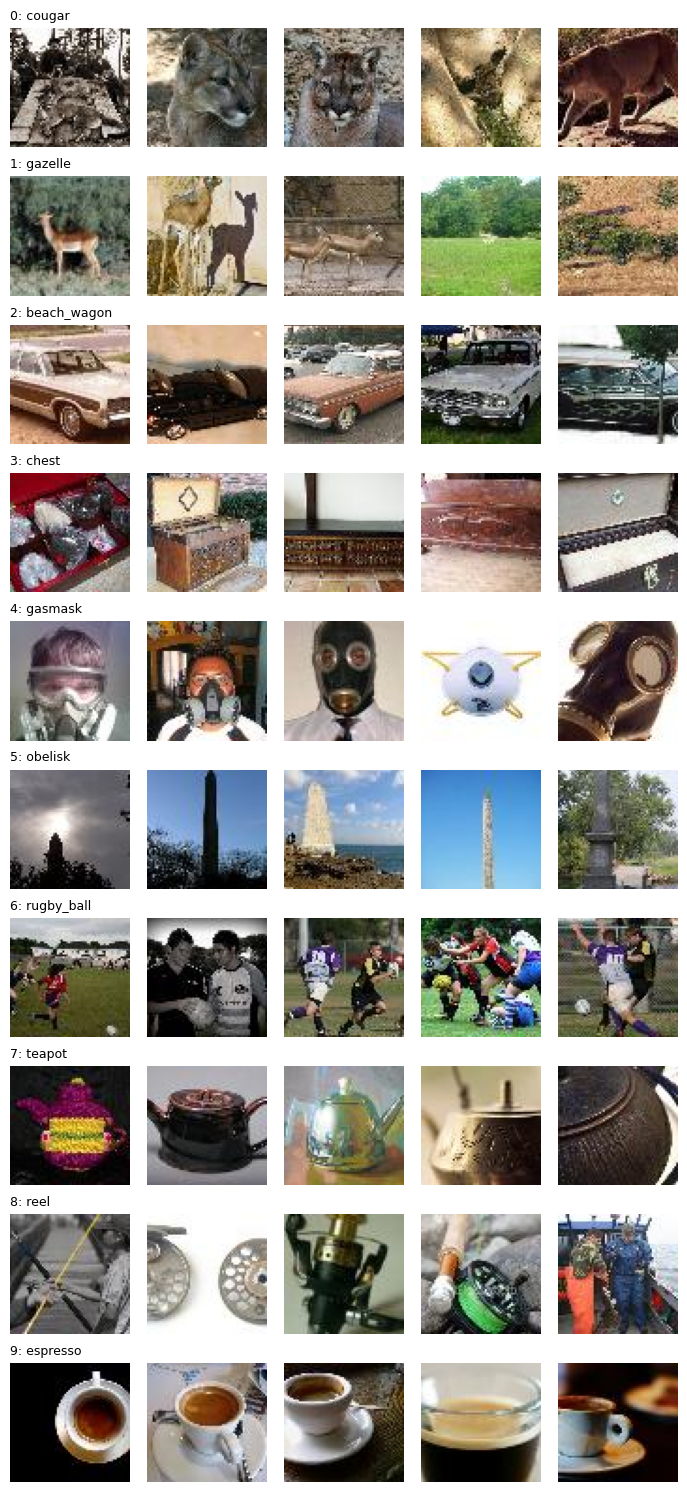

In [ ]:
labels_all = np.array(train_full["label"])
fig, axes = plt.subplots(10, 5, figsize=(7, 15))
for i in range(10):
    idx = np.where(labels_all == i)[0][:5]
    for ax, j in zip(axes[i], idx):
        ax.imshow(train_full[int(j)]["image"].convert("RGB"))
        ax.axis("off")
    axes[i, 0].set_title(f"{i}: {class_names[i]}", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
def to_arrays(hf_split):
    X = np.stack([np.array(img.convert("RGB"), dtype=np.uint8) for img in hf_split["image"]])
    y = np.array(hf_split["label"], dtype=np.int64)
    return X, y

X_all, y_all = to_arrays(train_full)
print("X_all:", X_all.shape, X_all.dtype, "| y_all:", y_all.shape)
print("Images per class:", np.bincount(y_all))

X_all: (5000, 64, 64, 3) uint8 | y_all: (5000,)
Images per class: [500 500 500 500 500 500 500 500 500 500]


In [ ]:
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)),
    test_size=500,
    stratify=y_all,
    random_state=SEED,
    shuffle=True,
)
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val,   y_val   = X_all[idx_val],   y_all[idx_val]

print("Train:", X_train.shape, "per class:", np.bincount(y_train))
print("Val  :", X_val.shape,   "per class:", np.bincount(y_val))
assert (np.bincount(y_train) == 450).all() and (np.bincount(y_val) == 50).all()
assert len(set(idx_train) & set(idx_val)) == 0

Train: (4500, 64, 64, 3) per class: [450 450 450 450 450 450 450 450 450 450]
Val  : (500, 64, 64, 3) per class: [50 50 50 50 50 50 50 50 50 50]


In [ ]:
def to_tensor01(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).float() / 255.0   # (N, 3, 64, 64)

Xtr = to_tensor01(X_train)
Xva = to_tensor01(X_val)

MEAN = Xtr.mean(dim=(0, 2, 3), keepdim=True)    # per-channel, training set only
STD  = Xtr.std(dim=(0, 2, 3), keepdim=True)
print("Channel mean:", MEAN.flatten().numpy().round(4))
print("Channel std :", STD.flatten().numpy().round(4))

def normalise(X):
    return (X - MEAN) / STD

Xtr_n = normalise(Xtr)
Xva_n = normalise(Xva)
ytr = torch.from_numpy(y_train)
yva = torch.from_numpy(y_val)

print("Train tensor:", tuple(Xtr_n.shape), "| mean ~ 0:", round(Xtr_n.mean().item(), 4), "| std ~ 1:", round(Xtr_n.std().item(), 4))
print("Val tensor  :", tuple(Xva_n.shape))

Channel mean: [0.4818 0.4508 0.4042]
Channel std : [0.2726 0.2692 0.2821]
Train tensor: (4500, 3, 64, 64) | mean ~ 0: 0.0 | std ~ 1: 1.0
Val tensor  : (500, 3, 64, 64)


In [ ]:
train_ds = TensorDataset(Xtr_n, ytr)
val_ds   = TensorDataset(Xva_n, yva)

def make_loaders(batch_size=64, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=gen)
    val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False)   # evaluation only, no weight updates
    return train_loader, val_loader

train_loader, val_loader = make_loaders(64)
xb, yb = next(iter(train_loader))
print("One batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))

One batch: (64, 3, 64, 64) (64,) | batches per epoch: 71


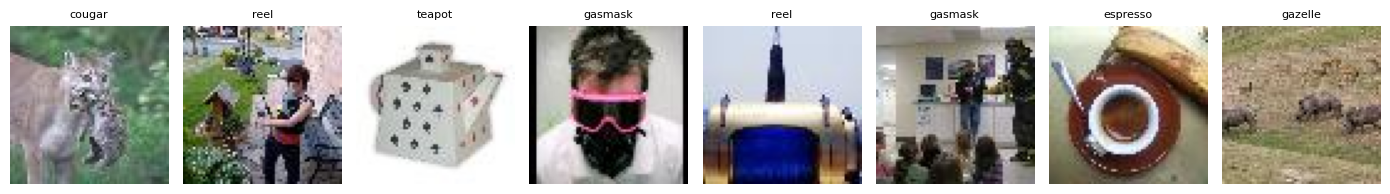

In [ ]:
imgs = (xb[:8] * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, im, lab in zip(axes, imgs, yb[:8]):
    ax.imshow(im); ax.axis("off"); ax.set_title(class_names[lab], fontsize=8)
plt.tight_layout(); plt.show()

2. Baseline models

In [ ]:
import copy, time
import torch.nn as nn

RESULTS = {}   # stores the history of every run, reused for comparisons in Sections 3–5

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                     # forward pass -> logits (N, 10)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()                 # backpropagation
                optimizer.step()                # Adam update
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n


def train_model(model_fn, name, epochs=30, lr=1e-3, batch_size=64, seed=SEED, verbose=True):
    set_seed(seed)
    model = model_fn().to(device)
    train_loader, val_loader = make_loaders(batch_size, seed)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
            "lr": lr, "batch_size": batch_size, "epochs": epochs}
    best_acc, best_state = -1.0, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
        if verbose:
            print(f"[{name}] epoch {ep:2d}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.3f}")
    hist["time_s"] = time.time() - t0
    print(f"[{name}] finished in {hist['time_s']:.0f} s")
    RESULTS[name] = hist
    final_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)      # keep the best-validation weights for later use
    return model, hist, final_state

In [ ]:
def plot_history(hist, title):
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    best = int(np.argmax(hist["val_acc"])) + 1
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(ep, hist["train_loss"], label="train"); a1.plot(ep, hist["val_loss"], label="validation")
    a1.set(title=f"{title}: loss", xlabel="epoch", ylabel="cross-entropy loss")
    a2.plot(ep, np.array(hist["train_acc"]) * 100, label="train"); a2.plot(ep, np.array(hist["val_acc"]) * 100, label="validation")
    a2.axvline(best, ls="--", c="grey", lw=1, label=f"best val (epoch {best})")
    a2.set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy (%)")
    for a in (a1, a2):
        a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def fit_report(hist, name):
    tr_acc, va_acc = np.array(hist["train_acc"]) * 100, np.array(hist["val_acc"]) * 100
    va_loss = np.array(hist["val_loss"])
    b = int(np.argmax(va_acc))
    m = int(np.argmin(va_loss))
    print(f"=== {name} ===")
    print(f"Best validation accuracy : {va_acc[b]:.1f}% at epoch {b+1}")
    print(f"Train acc at that epoch  : {tr_acc[b]:.1f}%  -> gap {tr_acc[b]-va_acc[b]:.1f} points")
    print(f"Final epoch ({len(va_acc)})          : train {tr_acc[-1]:.1f}%, val {va_acc[-1]:.1f}% -> gap {tr_acc[-1]-va_acc[-1]:.1f} points")
    print(f"Lowest validation loss   : {va_loss[m]:.3f} at epoch {m+1} (final val loss {va_loss[-1]:.3f})")
    if m + 1 < len(va_loss) and va_loss[-1] > va_loss[m] * 1.10:
        print(f"-> Validation loss rises after epoch {m+1} while training keeps improving: overfitting starts around epoch {m+1}.")
    else:
        print("-> Validation loss has not clearly risen: no strong sign of overfitting.")


def count_params(model):
    print(f"{'layer':<28}{'shape':<22}{'params':>12}")
    total = 0
    for n, p in model.named_parameters():
        if p.requires_grad:
            print(f"{n:<28}{str(tuple(p.shape)):<22}{p.numel():>12,}")
            total += p.numel()
    print(f"{'TOTAL':<50}{total:>12,}")
    return total

2b. Baseline A1: MLP (12288 → 128 → 64 → 10)

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                 # (N, 3, 64, 64) -> (N, 12288)
            nn.Linear(12288, 128), nn.ReLU(),
            nn.Linear(128, 64),    nn.ReLU(),
            nn.Linear(64, 10),            # logits
        )
    def forward(self, x):
        return self.net(x)

print(MLP())

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
n_mlp = count_params(MLP())
assert n_mlp == 1_581_898

layer                       shape                       params
net.1.weight                (128, 12288)             1,572,864
net.1.bias                  (128,)                         128
net.3.weight                (64, 128)                    8,192
net.3.bias                  (64,)                           64
net.5.weight                (10, 64)                       640
net.5.bias                  (10,)                           10
TOTAL                                                1,581,898


In [ ]:
mlp_model, mlp_hist, _ = train_model(MLP, "A1_MLP", epochs=30, lr=1e-3, batch_size=64)

[A1_MLP] epoch  1/30 | train loss 2.062 acc 0.303 | val loss 1.976 acc 0.336
[A1_MLP] epoch  2/30 | train loss 1.623 acc 0.448 | val loss 1.995 acc 0.366
[A1_MLP] epoch  3/30 | train loss 1.373 acc 0.544 | val loss 2.100 acc 0.358
[A1_MLP] epoch  4/30 | train loss 1.126 acc 0.632 | val loss 2.164 acc 0.364
[A1_MLP] epoch  5/30 | train loss 0.907 acc 0.711 | val loss 2.284 acc 0.358
[A1_MLP] epoch  6/30 | train loss 0.697 acc 0.786 | val loss 2.396 acc 0.340
[A1_MLP] epoch  7/30 | train loss 0.563 acc 0.833 | val loss 2.523 acc 0.362
[A1_MLP] epoch  8/30 | train loss 0.458 acc 0.869 | val loss 2.675 acc 0.354
[A1_MLP] epoch  9/30 | train loss 0.352 acc 0.899 | val loss 2.949 acc 0.346
[A1_MLP] epoch 10/30 | train loss 0.264 acc 0.923 | val loss 3.056 acc 0.364
[A1_MLP] epoch 11/30 | train loss 0.203 acc 0.942 | val loss 3.415 acc 0.336
[A1_MLP] epoch 12/30 | train loss 0.141 acc 0.964 | val loss 3.391 acc 0.340
[A1_MLP] epoch 13/30 | train loss 0.141 acc 0.964 | val loss 3.570 acc 0.354

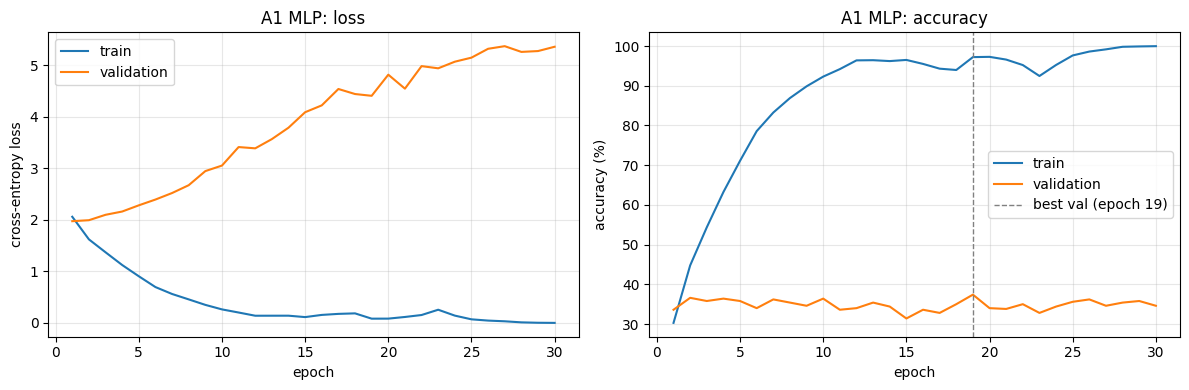

=== A1 MLP ===
Best validation accuracy : 37.4% at epoch 19
Train acc at that epoch  : 97.2%  -> gap 59.8 points
Final epoch (30)          : train 100.0%, val 34.6% -> gap 65.4 points
Lowest validation loss   : 1.976 at epoch 1 (final val loss 5.363)
-> Validation loss rises after epoch 1 while training keeps improving: overfitting starts around epoch 1.


In [ ]:
plot_history(mlp_hist, "A1 MLP")
fit_report(mlp_hist, "A1 MLP")

2c. Baseline A2: CNN

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                    # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),                    # 32 -> 16
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                             # 64*16*16 = 16384
            nn.Linear(64 * 16 * 16, 1024), nn.ReLU(),
            nn.Linear(1024, 10),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# Shape check: follow one dummy image through the network
x = torch.zeros(1, 3, 64, 64)
m = BaselineCNN()
for layer in list(m.features) + list(m.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:<10} -> {tuple(x.shape)}")

Conv2d     -> (1, 32, 64, 64)
ReLU       -> (1, 32, 64, 64)
MaxPool2d  -> (1, 32, 32, 32)
Conv2d     -> (1, 64, 32, 32)
ReLU       -> (1, 64, 32, 32)
MaxPool2d  -> (1, 64, 16, 16)
Flatten    -> (1, 16384)
Linear     -> (1, 1024)
ReLU       -> (1, 1024)
Linear     -> (1, 10)


In [ ]:
n_cnn = count_params(BaselineCNN())
assert n_cnn == 16_807_882
print(f"CNN / MLP parameter ratio: {n_cnn / n_mlp:.1f}x")

layer                       shape                       params
features.0.weight           (32, 3, 3, 3)                  864
features.0.bias             (32,)                           32
features.3.weight           (64, 32, 3, 3)              18,432
features.3.bias             (64,)                           64
classifier.1.weight         (1024, 16384)           16,777,216
classifier.1.bias           (1024,)                      1,024
classifier.3.weight         (10, 1024)                  10,240
classifier.3.bias           (10,)                           10
TOTAL                                               16,807,882
CNN / MLP parameter ratio: 10.6x


In [ ]:
cnn_model, cnn_hist, cnn_final_state = train_model(BaselineCNN, "A2_CNN", epochs=30, lr=1e-3, batch_size=64)

[A2_CNN] epoch  1/30 | train loss 2.158 acc 0.256 | val loss 1.785 acc 0.380
[A2_CNN] epoch  2/30 | train loss 1.563 acc 0.460 | val loss 1.558 acc 0.498
[A2_CNN] epoch  3/30 | train loss 1.245 acc 0.576 | val loss 1.356 acc 0.532
[A2_CNN] epoch  4/30 | train loss 0.972 acc 0.676 | val loss 1.338 acc 0.548
[A2_CNN] epoch  5/30 | train loss 0.694 acc 0.775 | val loss 1.428 acc 0.562
[A2_CNN] epoch  6/30 | train loss 0.430 acc 0.866 | val loss 1.498 acc 0.566
[A2_CNN] epoch  7/30 | train loss 0.180 acc 0.951 | val loss 1.830 acc 0.564
[A2_CNN] epoch  8/30 | train loss 0.070 acc 0.984 | val loss 1.940 acc 0.580
[A2_CNN] epoch  9/30 | train loss 0.021 acc 0.998 | val loss 2.198 acc 0.578
[A2_CNN] epoch 10/30 | train loss 0.008 acc 1.000 | val loss 2.246 acc 0.592
[A2_CNN] epoch 11/30 | train loss 0.003 acc 1.000 | val loss 2.350 acc 0.600
[A2_CNN] epoch 12/30 | train loss 0.001 acc 1.000 | val loss 2.453 acc 0.598
[A2_CNN] epoch 13/30 | train loss 0.001 acc 1.000 | val loss 2.524 acc 0.598

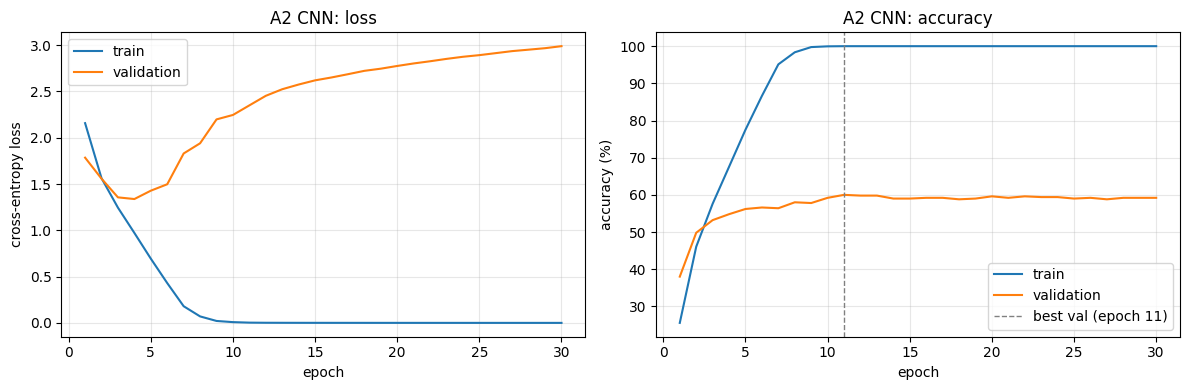

=== A2 CNN ===
Best validation accuracy : 60.0% at epoch 11
Train acc at that epoch  : 100.0%  -> gap 40.0 points
Final epoch (30)          : train 100.0%, val 59.2% -> gap 40.8 points
Lowest validation loss   : 1.338 at epoch 4 (final val loss 2.989)
-> Validation loss rises after epoch 4 while training keeps improving: overfitting starts around epoch 4.


In [ ]:
plot_history(cnn_hist, "A2 CNN")
fit_report(cnn_hist, "A2 CNN")

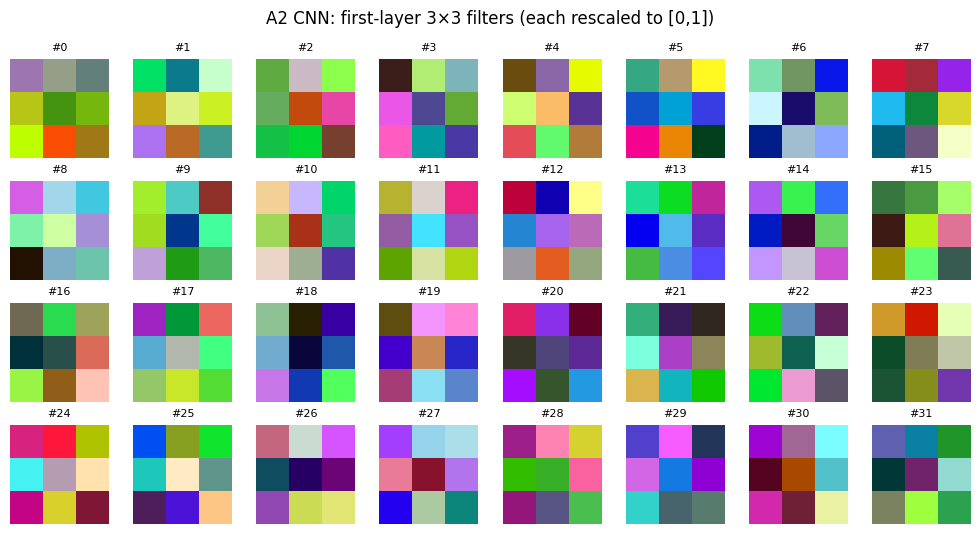

In [ ]:
W = cnn_model.features[0].weight.detach().cpu()           # (32, 3, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for i, ax in enumerate(axes.flat):
    f = W[i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)
    ax.imshow(f.permute(1, 2, 0).numpy(), interpolation="nearest")
    ax.set_title(f"#{i}", fontsize=8); ax.axis("off")
fig.suptitle("A2 CNN: first-layer 3×3 filters (each rescaled to [0,1])")
plt.tight_layout(); plt.show()

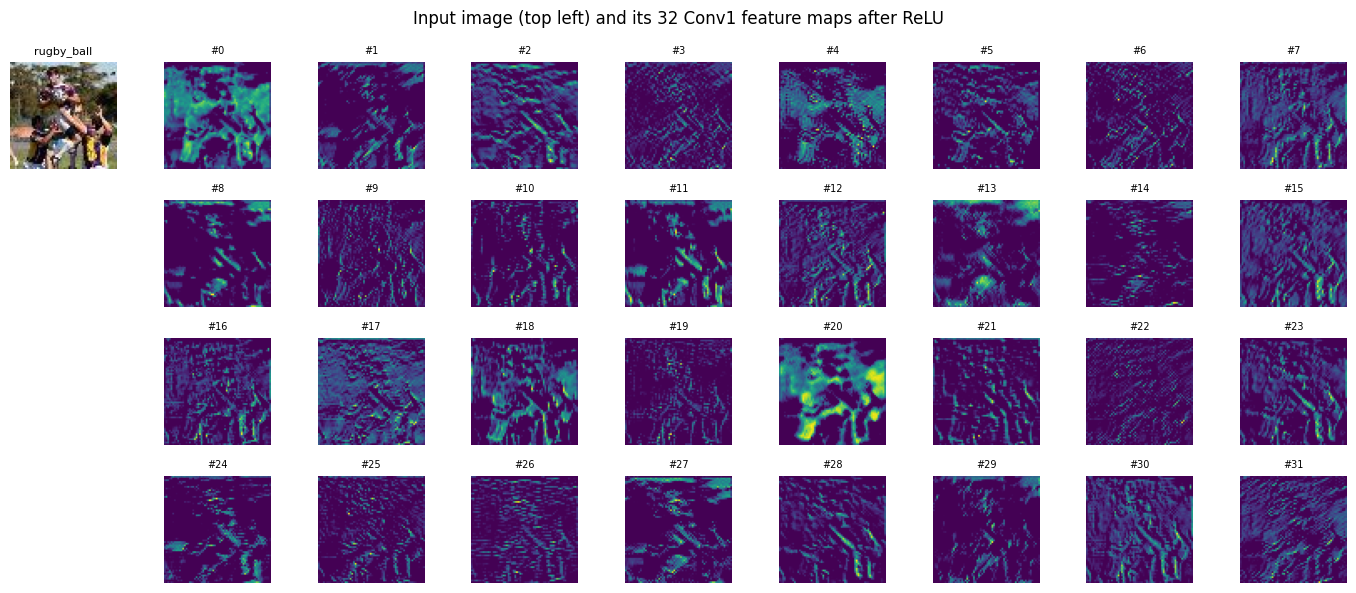

In [ ]:
img, lab = val_ds[0]
with torch.no_grad():
    fmap = torch.relu(cnn_model.features[0](img.unsqueeze(0).to(device)))[0].cpu()   # (32, 64, 64)

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(4, 9, 1)
ax.imshow((img.unsqueeze(0) * STD + MEAN)[0].clamp(0, 1).permute(1, 2, 0).numpy())
ax.set_title(class_names[lab], fontsize=8); ax.axis("off")
for i in range(32):
    ax = fig.add_subplot(4, 9, i + 2 + i // 8)
    ax.imshow(fmap[i], cmap="viridis"); ax.set_title(f"#{i}", fontsize=7); ax.axis("off")
fig.suptitle("Input image (top left) and its 32 Conv1 feature maps after ReLU")
plt.tight_layout(); plt.show()

Baseline comparison

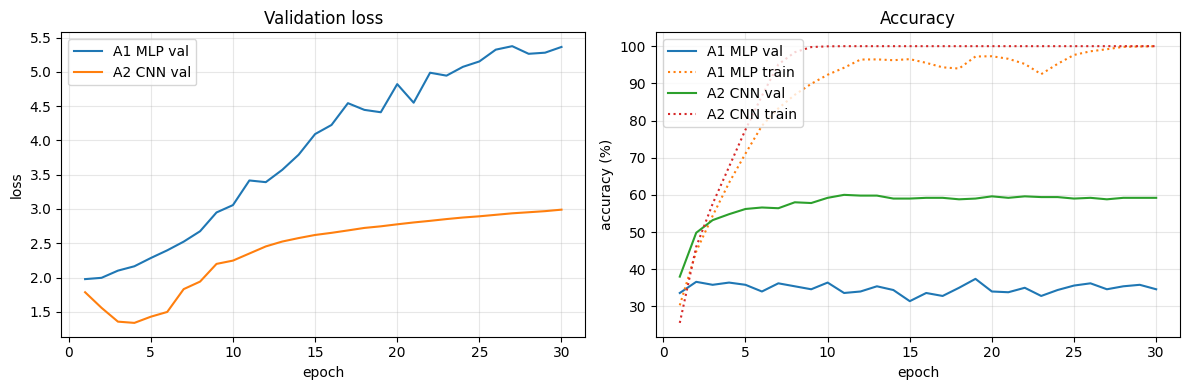

Model             Params   Best val acc   Epoch   Final gap  Time (s)
A1 MLP         1,581,898          37.4%      19       65.4%        11
A2 CNN        16,807,882          60.0%      11       40.8%        42


In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [("A1 MLP", mlp_hist), ("A2 CNN", cnn_hist)]:
    ep = np.arange(1, len(h["val_acc"]) + 1)
    a1.plot(ep, h["val_loss"], label=f"{name} val")
    a2.plot(ep, np.array(h["val_acc"]) * 100, label=f"{name} val")
    a2.plot(ep, np.array(h["train_acc"]) * 100, ls=":", label=f"{name} train")
a1.set(title="Validation loss", xlabel="epoch", ylabel="loss")
a2.set(title="Accuracy", xlabel="epoch", ylabel="accuracy (%)")
for a in (a1, a2):
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Model':<10}{'Params':>14}{'Best val acc':>15}{'Epoch':>8}{'Final gap':>12}{'Time (s)':>10}")
for name, h, n in [("A1 MLP", mlp_hist, n_mlp), ("A2 CNN", cnn_hist, n_cnn)]:
    b = int(np.argmax(h["val_acc"]))
    gap = (h["train_acc"][-1] - h["val_acc"][-1]) * 100
    print(f"{name:<10}{n:>14,}{h['val_acc'][b]*100:>14.1f}%{b+1:>8}{gap:>11.1f}%{h['time_s']:>10.0f}")

In [ ]:
import math

# ---- Section 3 configuration ------------------------------------------------------------
LR_BASE      = 1e-3                      # learning rate used in Section 2 (Adam)
BS_BASE      = 64                        # mini-batch size used in Section 2 (fixed by the brief)
EPOCHS_S3    = 5                         # short exploratory runs
FINAL_EPOCHS = 30                        # full budget for the final run (same as the baselines; brief allows 20-50)
BATCH_SIZES  = [16, 64, 256]             # study 1 (lr fixed at LR_BASE)
LEARN_RATES  = [1e-4, 1e-3, 1e-2]        # study 2 (batch size fixed at BS_BASE): 0.1x, 1x, 10x
assert math.isclose(LEARN_RATES[0], LR_BASE * 0.1) and math.isclose(LEARN_RATES[1], LR_BASE) \
       and math.isclose(LEARN_RATES[2], LR_BASE * 10)
assert BS_BASE in BATCH_SIZES and LR_BASE in LEARN_RATES

def bs_label(bs):
    return f"bs={bs}" + (" (Section 2)" if bs == BS_BASE else "")

def lr_label(lr):
    tag = {LEARN_RATES[0]: " (0.1x)", LEARN_RATES[1]: " (Section 2)", LEARN_RATES[2]: " (10x)"}[lr]
    return f"lr={lr:.0e}{tag}"

def get_run(bs, lr, epochs=EPOCHS_S3):
    # Train (or reuse) one exploratory run of the A2 CNN. The shared reference run is therefore trained only once.
    name = f"S3_bs{bs}_lr{lr:g}_ep{epochs}"
    if name not in RESULTS:
        train_model(BaselineCNN, name, epochs=epochs, lr=lr, batch_size=bs)
    return RESULTS[name]

def _min_val_loss(h):
    vl = np.array(h["val_loss"], dtype=float)
    vl = vl[np.isfinite(vl)]
    return float(vl.min()) if len(vl) else float("inf")

def _argmin_loss(h):
    vl = np.array(h["val_loss"], dtype=float)
    return int(np.argmin(np.where(np.isfinite(vl), vl, np.inf)))

def summary_table(runs):
    hdr = (f"{'Setting':<24}{'Best val acc':>13}{'@ep':>5}{'Train@best':>12}{'Min val loss':>14}{'@ep':>5}"
           f"{'Final val loss':>16}{'Updates/ep':>12}{'Time (s)':>10}")
    print(hdr); print("-" * len(hdr))
    for label, h in runs.items():
        va, ta = np.array(h["val_acc"]) * 100, np.array(h["train_acc"]) * 100
        vl = np.array(h["val_loss"], dtype=float)
        b, m = int(np.argmax(va)), _argmin_loss(h)
        upd = math.ceil(len(train_ds) / h["batch_size"])
        flag = "   <- stays near chance (10%): did not learn" if va[b] <= 15 else ""
        print(f"{label:<24}{va[b]:>12.1f}%{b+1:>5}{ta[b]:>11.1f}%{vl[m]:>14.3f}{m+1:>5}{vl[-1]:>16.3f}{upd:>12}{h['time_s']:>10.0f}{flag}")

def select_best(runs, what):
    # rank by best validation accuracy; exact ties -> lower minimum validation loss
    ranked = sorted(runs.items(), key=lambda kv: (-max(kv[1]["val_acc"]), _min_val_loss(kv[1])))
    print(f"Ranking by best validation accuracy ({what}):")
    for r, (label, h) in enumerate(ranked, 1):
        b = int(np.argmax(h["val_acc"]))
        print(f"  {r}. {label:<24} best val acc {h['val_acc'][b]*100:.1f}% (epoch {b+1}), min val loss {_min_val_loss(h):.3f}")
    best_label, best_h = ranked[0]
    p = max(best_h["val_acc"])
    se = 100 * math.sqrt(p * (1 - p) / len(val_ds))
    margin = (p - max(ranked[1][1]["val_acc"])) * 100
    msg = (f"-> Best {what}: {best_label}. Lead over the runner-up: {margin:.1f} points "
           f"(one standard error of a {len(val_ds)}-image validation accuracy is about {se:.1f} points)")
    msg += "; the lead is within sampling noise, so treat the top options as close." if margin <= se else "."
    print(msg)
    return best_label, best_h

def compare_plot(runs, suptitle, log_loss=False):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    panels = [("train_loss", "Training loss", 1), ("val_loss", "Validation loss", 1),
              ("train_acc", "Training accuracy (%)", 100), ("val_acc", "Validation accuracy (%)", 100)]
    for ax, (key, title, scale) in zip(axes.flat, panels):
        for label, h in runs.items():
            y = np.array(h[key], dtype=float) * scale
            ep = np.arange(1, len(y) + 1)
            line, = ax.plot(ep, y, marker="o", ms=4, label=label)
            if key == "val_acc":                                   # star = best validation epoch
                b = int(np.argmax(y)); ax.scatter([b + 1], [y[b]], marker="*", s=160, color=line.get_color(), zorder=5)
        if scale == 100:
            ax.axhline(10, ls=":", c="grey", lw=1, label="chance (10%)")
        elif log_loss:
            ax.set_yscale("log"); title += " (log scale)"
        ax.set(title=title, xlabel="epoch", ylabel="accuracy (%)" if scale == 100 else "cross-entropy loss")
        ax.set_xticks(ep); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout(); plt.show()

In [ ]:
ref_hist = get_run(BS_BASE, LR_BASE)

base5_val = np.array(RESULTS["A2_CNN"]["val_acc"][:EPOCHS_S3])
base5_trl = np.array(RESULTS["A2_CNN"]["train_loss"][:EPOCHS_S3])
d_val = np.abs(np.array(ref_hist["val_acc"]) - base5_val).max() * 100
d_trl = np.abs(np.array(ref_hist["train_loss"]) - base5_trl).max()
print(f"\nMax difference to the first {EPOCHS_S3} epochs of the Section 2 A2 CNN run: "
      f"val acc {d_val:.2f} points, train loss {d_trl:.4f}")
print("-> identical to Section 2." if d_val == 0 and d_trl < 1e-6 else
      "-> tiny differences can only come from GPU non-determinism; the set-up is otherwise identical.")

[S3_bs64_lr0.001_ep5] epoch  1/5 | train loss 2.158 acc 0.256 | val loss 1.785 acc 0.380
[S3_bs64_lr0.001_ep5] epoch  2/5 | train loss 1.563 acc 0.460 | val loss 1.558 acc 0.498
[S3_bs64_lr0.001_ep5] epoch  3/5 | train loss 1.245 acc 0.576 | val loss 1.356 acc 0.532
[S3_bs64_lr0.001_ep5] epoch  4/5 | train loss 0.972 acc 0.676 | val loss 1.338 acc 0.548
[S3_bs64_lr0.001_ep5] epoch  5/5 | train loss 0.694 acc 0.775 | val loss 1.428 acc 0.562
[S3_bs64_lr0.001_ep5] finished in 7 s

Max difference to the first 5 epochs of the Section 2 A2 CNN run: val acc 0.00 points, train loss 0.0000
-> identical to Section 2.


In [ ]:
runs_bs = {}
for bs in BATCH_SIZES:
    runs_bs[bs_label(bs)] = get_run(bs, LR_BASE)

print(f"\n=== Study 1: batch size (lr = {LR_BASE:g}, {EPOCHS_S3} epochs) ===")
summary_table(runs_bs)
print()
best_bs_label, best_bs_hist = select_best(runs_bs, "batch size")
best_bs = best_bs_hist["batch_size"]
print(f"Chosen batch size: {best_bs}")

[S3_bs16_lr0.001_ep5] epoch  1/5 | train loss 1.777 acc 0.389 | val loss 1.548 acc 0.486
[S3_bs16_lr0.001_ep5] epoch  2/5 | train loss 1.246 acc 0.571 | val loss 1.355 acc 0.574
[S3_bs16_lr0.001_ep5] epoch  3/5 | train loss 0.746 acc 0.749 | val loss 1.406 acc 0.522
[S3_bs16_lr0.001_ep5] epoch  4/5 | train loss 0.333 acc 0.889 | val loss 1.686 acc 0.582
[S3_bs16_lr0.001_ep5] epoch  5/5 | train loss 0.116 acc 0.962 | val loss 1.929 acc 0.588
[S3_bs16_lr0.001_ep5] finished in 20 s
[S3_bs256_lr0.001_ep5] epoch  1/5 | train loss 2.458 acc 0.213 | val loss 2.069 acc 0.298
[S3_bs256_lr0.001_ep5] epoch  2/5 | train loss 1.854 acc 0.364 | val loss 1.801 acc 0.414
[S3_bs256_lr0.001_ep5] epoch  3/5 | train loss 1.585 acc 0.470 | val loss 1.665 acc 0.468
[S3_bs256_lr0.001_ep5] epoch  4/5 | train loss 1.389 acc 0.533 | val loss 1.518 acc 0.518
[S3_bs256_lr0.001_ep5] epoch  5/5 | train loss 1.208 acc 0.589 | val loss 1.421 acc 0.550
[S3_bs256_lr0.001_ep5] finished in 6 s

=== Study 1: batch size (l

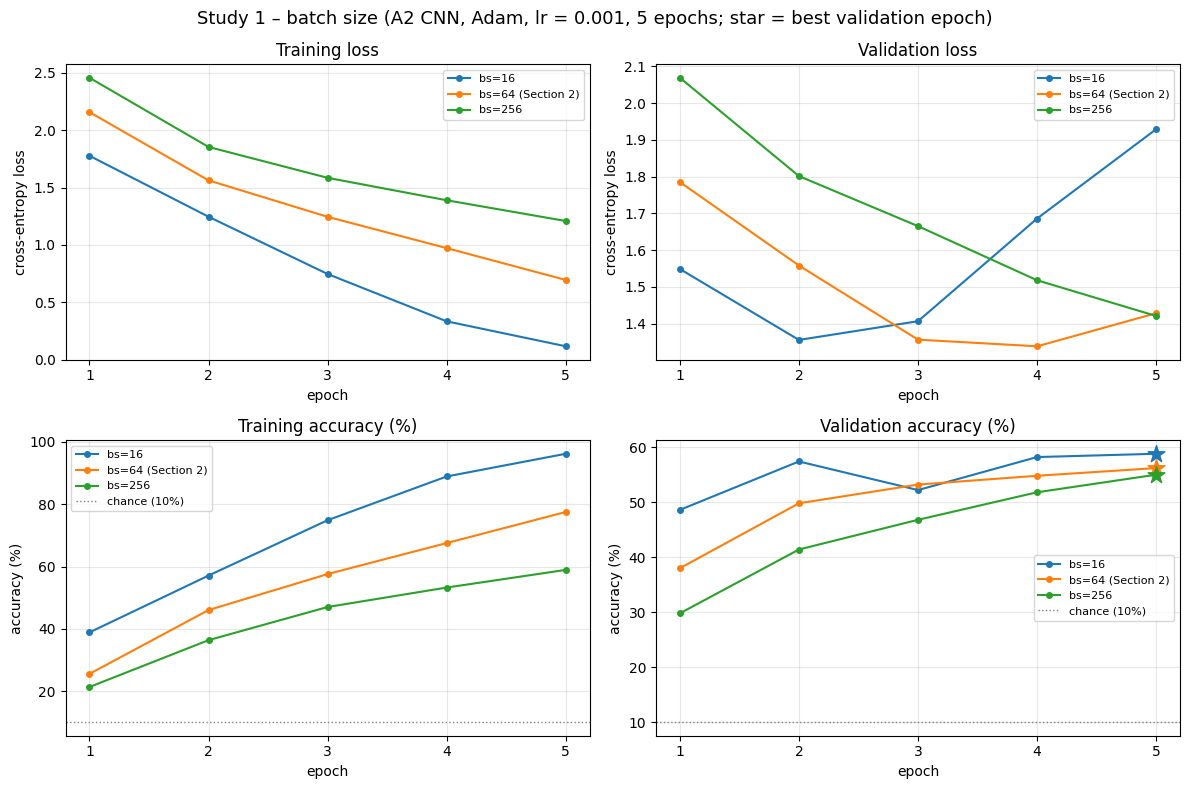

In [ ]:
compare_plot(runs_bs, f"Study 1 – batch size (A2 CNN, Adam, lr = {LR_BASE:g}, {EPOCHS_S3} epochs; star = best validation epoch)")

In [ ]:
runs_lr = {}
for lr in LEARN_RATES:
    runs_lr[lr_label(lr)] = get_run(BS_BASE, lr)

print(f"\n=== Study 2: learning rate (batch size = {BS_BASE}, {EPOCHS_S3} epochs) ===")
summary_table(runs_lr)
print()
best_lr_label, best_lr_hist = select_best(runs_lr, "learning rate")
best_lr = best_lr_hist["lr"]
print(f"Chosen learning rate: {best_lr:g}")

[S3_bs64_lr0.0001_ep5] epoch  1/5 | train loss 1.925 acc 0.346 | val loss 1.727 acc 0.436
[S3_bs64_lr0.0001_ep5] epoch  2/5 | train loss 1.518 acc 0.504 | val loss 1.639 acc 0.476
[S3_bs64_lr0.0001_ep5] epoch  3/5 | train loss 1.357 acc 0.557 | val loss 1.522 acc 0.476
[S3_bs64_lr0.0001_ep5] epoch  4/5 | train loss 1.223 acc 0.613 | val loss 1.469 acc 0.510
[S3_bs64_lr0.0001_ep5] epoch  5/5 | train loss 1.127 acc 0.638 | val loss 1.413 acc 0.532
[S3_bs64_lr0.0001_ep5] finished in 7 s
[S3_bs64_lr0.01_ep5] epoch  1/5 | train loss 5.557 acc 0.092 | val loss 2.303 acc 0.100
[S3_bs64_lr0.01_ep5] epoch  2/5 | train loss 2.304 acc 0.091 | val loss 2.303 acc 0.100
[S3_bs64_lr0.01_ep5] epoch  3/5 | train loss 2.304 acc 0.092 | val loss 2.303 acc 0.100
[S3_bs64_lr0.01_ep5] epoch  4/5 | train loss 2.304 acc 0.095 | val loss 2.303 acc 0.100
[S3_bs64_lr0.01_ep5] epoch  5/5 | train loss 2.304 acc 0.095 | val loss 2.303 acc 0.100
[S3_bs64_lr0.01_ep5] finished in 7 s

=== Study 2: learning rate (batch

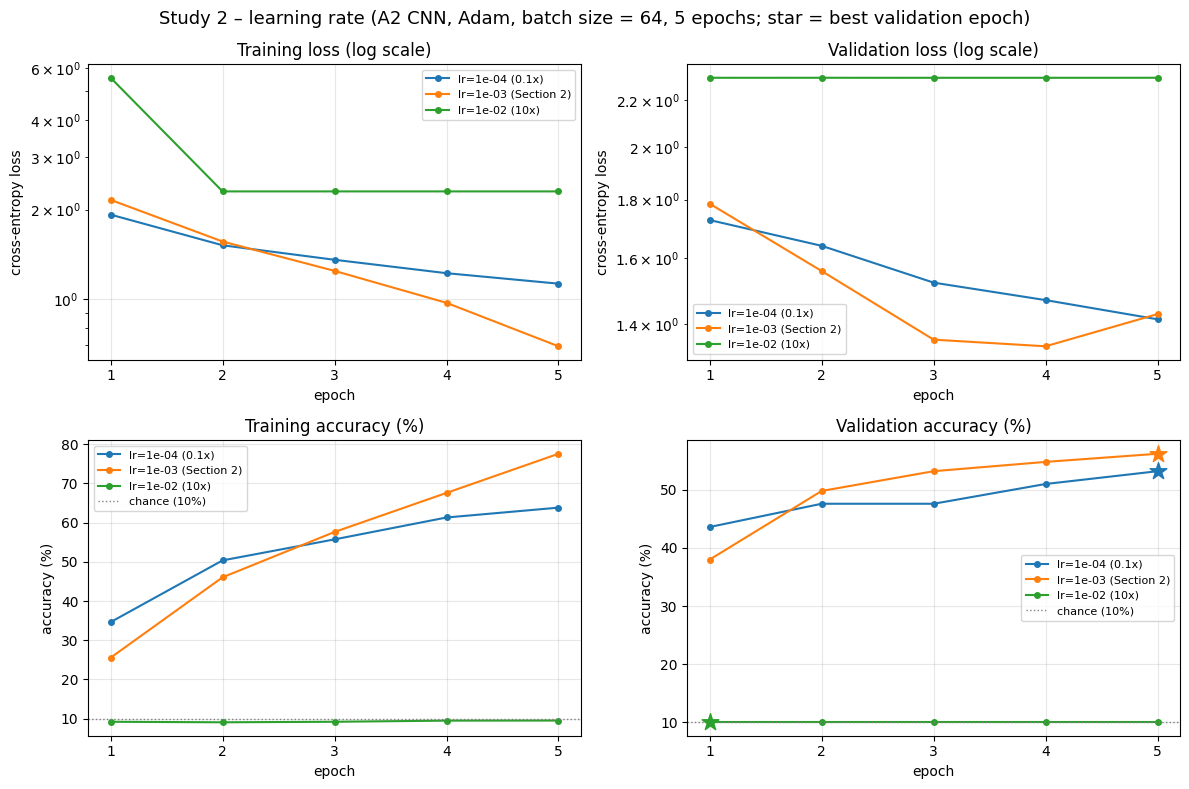

In [ ]:
compare_plot(runs_lr, f"Study 2 – learning rate (A2 CNN, Adam, batch size = {BS_BASE}, {EPOCHS_S3} epochs; star = best validation epoch)", log_loss=True)

In [ ]:
print(f"Best combination: batch size = {best_bs}, learning rate = {best_lr:g} "
      f"(Section 2 reference: batch size = {BS_BASE}, learning rate = {LR_BASE:g})")
if best_bs == BS_BASE and best_lr == LR_BASE:
    print("Note: the best combination equals the Section 2 reference, so this run reproduces the A2 baseline.")

tuned_model, tuned_hist, tuned_final_state = train_model(
    BaselineCNN, "A2_CNN_tuned", epochs=FINAL_EPOCHS, lr=best_lr, batch_size=best_bs)

n_tuned = sum(p.numel() for p in tuned_model.parameters() if p.requires_grad)
assert n_tuned == n_cnn            # same architecture as the A2 baseline: 16,807,882 parameters
print(f"Parameters: {n_tuned:,} (identical to the A2 baseline)")

Best combination: batch size = 16, learning rate = 0.001 (Section 2 reference: batch size = 64, learning rate = 0.001)
[A2_CNN_tuned] epoch  1/30 | train loss 1.777 acc 0.389 | val loss 1.548 acc 0.486
[A2_CNN_tuned] epoch  2/30 | train loss 1.246 acc 0.571 | val loss 1.355 acc 0.574
[A2_CNN_tuned] epoch  3/30 | train loss 0.746 acc 0.749 | val loss 1.406 acc 0.522
[A2_CNN_tuned] epoch  4/30 | train loss 0.333 acc 0.889 | val loss 1.686 acc 0.582
[A2_CNN_tuned] epoch  5/30 | train loss 0.116 acc 0.962 | val loss 1.929 acc 0.588
[A2_CNN_tuned] epoch  6/30 | train loss 0.036 acc 0.990 | val loss 2.369 acc 0.574
[A2_CNN_tuned] epoch  7/30 | train loss 0.045 acc 0.986 | val loss 2.573 acc 0.536
[A2_CNN_tuned] epoch  8/30 | train loss 0.069 acc 0.979 | val loss 2.688 acc 0.552
[A2_CNN_tuned] epoch  9/30 | train loss 0.031 acc 0.991 | val loss 2.722 acc 0.554
[A2_CNN_tuned] epoch 10/30 | train loss 0.017 acc 0.995 | val loss 3.144 acc 0.560
[A2_CNN_tuned] epoch 11/30 | train loss 0.121 acc 0

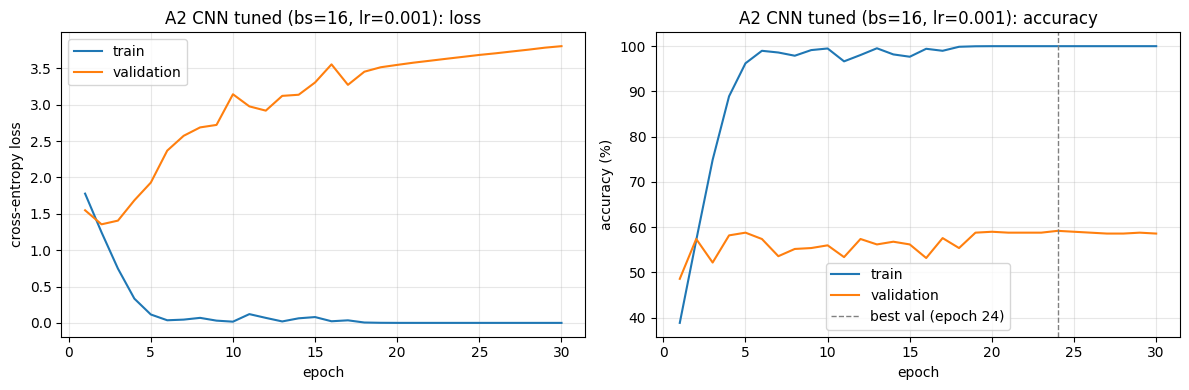

=== A2 CNN tuned (bs=16, lr=0.001) ===
Best validation accuracy : 59.2% at epoch 24
Train acc at that epoch  : 100.0%  -> gap 40.8 points
Final epoch (30)          : train 100.0%, val 58.6% -> gap 41.4 points
Lowest validation loss   : 1.355 at epoch 2 (final val loss 3.805)
-> Validation loss rises after epoch 2 while training keeps improving: overfitting starts around epoch 2.


In [ ]:
tuned_title = f"A2 CNN tuned (bs={best_bs}, lr={best_lr:g})"
plot_history(tuned_hist, tuned_title)
fit_report(tuned_hist, tuned_title)

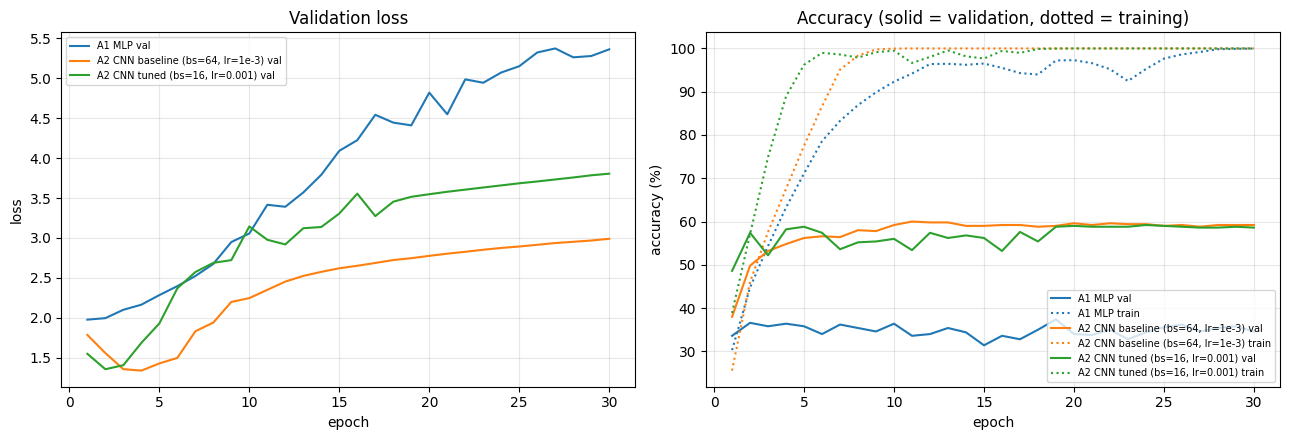

Model                                  bs       lr  Epochs       Params  Best val acc  Epoch  Min val loss  Final gap  Time (s)
A1 MLP                                 64    0.001      30    1,581,898         37.4%     19         1.976      65.4%        11
A2 CNN baseline (bs=64, lr=1e-3)       64    0.001      30   16,807,882         60.0%     11         1.338      40.8%        42
A2 CNN tuned (bs=16, lr=0.001)         16    0.001      30   16,807,882         59.2%     24         1.355      41.4%        90


In [ ]:
tuned_name = f"A2 CNN tuned (bs={best_bs}, lr={best_lr:g})"
cands = {
    "A1 MLP":                           (RESULTS["A1_MLP"],       n_mlp),
    "A2 CNN baseline (bs=64, lr=1e-3)": (RESULTS["A2_CNN"],       n_cnn),
    tuned_name:                         (RESULTS["A2_CNN_tuned"], n_tuned),
}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for i, (name, (h, _)) in enumerate(cands.items()):
    ep = np.arange(1, len(h["val_acc"]) + 1)
    a1.plot(ep, h["val_loss"], color=f"C{i}", label=f"{name} val")
    a2.plot(ep, np.array(h["val_acc"]) * 100, color=f"C{i}", label=f"{name} val")
    a2.plot(ep, np.array(h["train_acc"]) * 100, color=f"C{i}", ls=":", label=f"{name} train")
a1.set(title="Validation loss", xlabel="epoch", ylabel="loss")
a2.set(title="Accuracy (solid = validation, dotted = training)", xlabel="epoch", ylabel="accuracy (%)")
for a in (a1, a2):
    a.legend(fontsize=7); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Model':<36}{'bs':>5}{'lr':>9}{'Epochs':>8}{'Params':>13}{'Best val acc':>14}{'Epoch':>7}{'Min val loss':>14}{'Final gap':>11}{'Time (s)':>10}")
for name, (h, n) in cands.items():
    va, ta = np.array(h["val_acc"]) * 100, np.array(h["train_acc"]) * 100
    b = int(np.argmax(va)); gap = ta[-1] - va[-1]
    print(f"{name:<36}{h['batch_size']:>5}{h['lr']:>9g}{len(va):>8}{n:>13,}{va[b]:>13.1f}%{b+1:>7}{_min_val_loss(h):>14.3f}{gap:>10.1f}%{h['time_s']:>10.0f}")

In [ ]:
def model_stats(h, n_params):
    va, ta = np.array(h["val_acc"]) * 100, np.array(h["train_acc"]) * 100
    vl = np.array(h["val_loss"], dtype=float)
    b, m = int(np.argmax(va)), _argmin_loss(h)
    return dict(best=va[b], ep=b + 1, gap_best=ta[b] - va[b], minloss=vl[m], minloss_ep=m + 1,
                final_loss=vl[-1], final_gap=ta[-1] - va[-1], params=n_params, time=h["time_s"])

stats  = {name: model_stats(h, n) for name, (h, n) in cands.items()}
ranked = sorted(stats, key=lambda k: (-stats[k]["best"], stats[k]["minloss"]))
winner, second, third = ranked
W, S, T = stats[winner], stats[second], stats[third]
se = 100 * math.sqrt((W["best"] / 100) * (1 - W["best"] / 100) / len(val_ds))

print("=" * 78)
print(f"OPTIMAL MODEL: {winner}")
print("=" * 78)
print("Rationale")
print(f"1. Accuracy: it reaches the highest best validation accuracy, {W['best']:.1f}% (epoch {W['ep']}), "
      f"which is {W['best']-S['best']:.1f} points above {second} ({S['best']:.1f}%) and "
      f"{W['best']-T['best']:.1f} points above {third} ({T['best']:.1f}%).")
if W["best"] - S["best"] <= se:
    print(f"   Caution: the lead over the runner-up is within one standard error (about {se:.1f} points) of a "
          f"{len(val_ds)}-image validation accuracy, so these two models are statistically close; the criteria below decide.")
print("2. Generalisation (train - validation accuracy gap at each model's best epoch): " +
      "; ".join(f"{k}: {stats[k]['gap_best']:.1f} points" for k in stats) + ".")
lowest_loss = min(stats, key=lambda k: stats[k]["minloss"])
print(f"3. Validation loss: the lowest value is {stats[lowest_loss]['minloss']:.3f} ({lowest_loss}, epoch {stats[lowest_loss]['minloss_ep']}); "
      + ("this is the selected model." if lowest_loss == winner else
         f"the selected model's lowest is {W['minloss']:.3f} (epoch {W['minloss_ep']}), so it wins on accuracy but not on loss."))
if W["final_loss"] > 1.10 * W["minloss"]:
    print(f"4. Overfitting: the selected model's validation loss rises after epoch {W['minloss_ep']} "
          f"(final {W['final_loss']:.3f}) while training accuracy keeps improving (final gap {W['final_gap']:.1f} points). "
          f"train_model keeps the best-validation weights (epoch {W['ep']}), which should be used rather than the last epoch's.")
else:
    print(f"4. Overfitting: the selected model's validation loss has not clearly risen by the final epoch "
          f"(min {W['minloss']:.3f}, final {W['final_loss']:.3f}); final gap {W['final_gap']:.1f} points.")
print(f"5. Cost: {W['params']:,} parameters, {W['time']:.0f} s for {len(cands[winner][0]['val_acc'])} epochs.")
if W["final_gap"] > 10:
    print(f"6. Remaining limitation: even the selected model still overfits (final train-validation gap {W['final_gap']:.1f} points), "
          "so further gains must come from the model design and regularisation of Sections 4-5, not from batch size or learning rate alone.")
else:
    print(f"6. The selected model's final train-validation gap is small ({W['final_gap']:.1f} points), so it is not strongly overfitting.")
print("   All choices were made on the validation split only; the test set has not been used.")

OPTIMAL MODEL: A2 CNN baseline (bs=64, lr=1e-3)
Rationale
1. Accuracy: it reaches the highest best validation accuracy, 60.0% (epoch 11), which is 0.8 points above A2 CNN tuned (bs=16, lr=0.001) (59.2%) and 22.6 points above A1 MLP (37.4%).
   Caution: the lead over the runner-up is within one standard error (about 2.2 points) of a 500-image validation accuracy, so these two models are statistically close; the criteria below decide.
2. Generalisation (train - validation accuracy gap at each model's best epoch): A1 MLP: 59.8 points; A2 CNN baseline (bs=64, lr=1e-3): 40.0 points; A2 CNN tuned (bs=16, lr=0.001): 40.8 points.
3. Validation loss: the lowest value is 1.338 (A2 CNN baseline (bs=64, lr=1e-3), epoch 4); this is the selected model.
4. Overfitting: the selected model's validation loss rises after epoch 4 (final 2.989) while training accuracy keeps improving (final gap 40.8 points). train_model keeps the best-validation weights (epoch 11), which should be used rather than the last